In [1]:
# Setup
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

from pathlib import Path

import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
import torch
from chronos import Chronos2Pipeline

USE_FINETUNED = False

BASE_MODEL = "amazon/chronos-2"
LOCAL_CKPT = "chronos-2-tep-finetuned"
HF_REPO_ID = "Imker0311/chronos-2-tep-lora"


def resolve_checkpoint(finetuned):
    if not finetuned:
        return BASE_MODEL
    if Path(LOCAL_CKPT).is_dir():
        return LOCAL_CKPT
    from huggingface_hub import snapshot_download
    return snapshot_download(repo_id=HF_REPO_ID, repo_type="model")


device = "cuda" if torch.cuda.is_available() else "cpu"
CHECKPOINT = resolve_checkpoint(USE_FINETUNED)
kwargs = dict(device_map=device)
if USE_FINETUNED:
    kwargs["import_allowlist"] = ["chronos.chronos2.model"]
pipeline = Chronos2Pipeline.from_pretrained(CHECKPOINT, **kwargs)

MODEL_LABEL = "Chronos-2 fine-tuned" if USE_FINETUNED else "Chronos-2"
MAX_CONTEXT = pipeline.model_context_length
MAX_HORIZON = pipeline.model_prediction_length
print(f"Loaded {MODEL_LABEL} from {CHECKPOINT} on {device}")

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loaded Chronos-2 from amazon/chronos-2 on cpu


In [2]:
# Load data
import json
import TEP_Scenario_Simulation as sim

DATA_FILE = sim.DATA_FILE


def read_names(ds):
    return [n.decode() if isinstance(n, bytes) else str(n) for n in ds.attrs["names"]]


groups = {}
with h5py.File(DATA_FILE, "r") as f:
    time_s = f["t"][()]
    for key in ["xmeas", "xmv", "dist", "sp"]:
        groups[key] = (f[key][()], read_names(f[key]))
    groups["valve"] = (f["y"][:, 38:50], read_names(f["y"])[38:50])   # true valve positions
    dist_mean = f["state/dist_mean"][()]                               # disturbance means without the background noise
    config = json.loads(f.attrs["config"])
SAMPLE_MIN = config["record_every"] / 60   # sampling interval (min)
T_ORIGIN = pd.Timestamp("2026-01-01")

CHANGEABLE = [f"{g}_{i}" for g, i, _ in config["context_variables"]]          # disturbances and set points moved in the context
NOMINAL = {f"{g}_{i}": sim.nominal_value(g, i) for g, i, _ in config["context_variables"]}
LARGEST = {f"{g}_{i}": v for g, i, v in config["context_variables"]}          # largest change in the context


def off_nominal(dist_mean, sp):
    off = np.zeros(len(sp), dtype=bool)
    for col in CHANGEABLE:
        group, index = col.split("_")
        values = dist_mean[:, int(index) - 1] if group == "dist" else sp[:, int(index) - 1]
        off |= np.abs(values - NOMINAL[col]) > 0.02 * LARGEST[col]
    return off


data = {"time_h": time_s / 3600, "change": off_nominal(dist_mean, groups["sp"][0]).astype(int)}
COLUMNS, LABELS = {}, {}
for group, (values, labels) in groups.items():
    COLUMNS[group] = [f"{group}_{i}" for i in range(1, values.shape[1] + 1)]
    for col, v, label in zip(COLUMNS[group], values.T, labels):
        data[col] = v
        LABELS[col] = label

df = pd.DataFrame(data)
df.insert(0, "item_id", "tep")
df.insert(1, "timestamp", T_ORIGIN + pd.to_timedelta(time_s, unit="s"))

TARGET_COLUMNS = COLUMNS["xmeas"] + COLUMNS["xmv"]
print(f"{len(df)} samples ({df['time_h'].iloc[-1]:.0f} h), {len(TARGET_COLUMNS)} targets, covariate groups: "
      + ", ".join(f"{g} ({len(COLUMNS[g])})" for g in COLUMNS if g not in ["xmeas", "xmv"]))
print("changeable: " + ", ".join(f"{c} {LABELS[c]} (nominal {NOMINAL[c]:.4g})" for c in CHANGEABLE))
df.head()

3988 samples (399 h), 53 targets, covariate groups: dist (12), sp (20), valve (12)
changeable: dist_1 Feed 4 A fraction (nominal 0.485), dist_2 Feed 4 B fraction (nominal 0.005), dist_5 Reactor CW inlet temp (C) (nominal 35), dist_6 Condenser CW inlet temp (C) (nominal 40), sp_11 Stripper underflow (m3/h) (nominal 22.95), sp_18 Reactor temperature (C) (nominal 120.4), sp_19 Purge B (mol%) (nominal 13.82), sp_20 Product E (mol%) (nominal 0.8357)


,item_id,timestamp,time_h,change,xmeas_1,xmeas_2,xmeas_3,xmeas_4,xmeas_5,xmeas_6,...,valve_3,valve_4,valve_5,valve_6,valve_7,valve_8,valve_9,valve_10,valve_11,valve_12
0,tep,2026-01-01 00:06:00,0.1,0,0.250570,3646.911201,4529.162678,9.361689,26.955013,42.374920,...,24.683121,61.475781,22.362666,40.095187,38.412597,46.437197,47.494907,40.941809,17.066065,50.0
1,tep,2026-01-01 00:12:00,0.2,0,0.251641,3685.782817,4532.305731,9.392227,27.193076,42.307333,...,24.669825,61.221179,22.280518,39.990585,38.836422,46.077829,47.463707,40.761192,19.494301,50.0
2,tep,2026-01-01 00:18:00,0.3,0,0.224757,3649.557075,4485.151953,9.372481,26.672070,42.430783,...,21.888907,61.453883,22.134811,40.755224,37.089557,47.826073,47.577765,40.168011,16.870130,50.0
3,tep,2026-01-01 00:24:00,0.4,0,0.218361,3639.316195,4472.578992,9.491043,26.897292,42.106666,...,21.614867,61.544113,22.345583,40.749596,34.571792,46.723870,47.676774,40.859106,17.564538,50.0
4,tep,2026-01-01 00:30:00,0.5,0,0.259758,3665.946901,4583.161157,9.290830,27.026172,42.239414,...,25.668292,61.171410,21.855738,42.087173,38.106327,48.404313,47.792804,40.174173,18.057276,50.0


In [3]:
# Forecast start and operator change
START = None
HORIZON = 100         # forecast length in samples
PLOT_LEAD_IN = 200
TRUTH_SEED = 1        # noise seed of the simulated true response

CHANGES = [
    ("dist_6", -10.0, 5.0, 10.0),
]

SPLIT = len(df) if START is None else START
HORIZON = min(HORIZON, MAX_HORIZON)
context_used = min(SPLIT, MAX_CONTEXT)

state = sim.load_state(DATA_FILE, SPLIT - 1)   # simulator state at the last context sample
t0 = sim.state_time(state)
changes = []
for col, percent, delay, duration in CHANGES:
    if col not in CHANGEABLE:
        raise ValueError(f"{col} is not changeable (choose from {CHANGEABLE})")
    group, index = col.split("_")
    target = NOMINAL[col] * (1 + percent / 100)
    changes.append((group, int(index), t0 + delay, target, duration, 0.0))
    print(f"{col} {LABELS[col]}: {NOMINAL[col]:.4g} -> {target:.4g} ({percent:+.1f}%), "
          f"ramp {t0 + delay:.1f}-{t0 + delay + duration:.1f} h")

print(f"\nForecast from sample {SPLIT} ({t0 + SAMPLE_MIN / 60:.1f} h), horizon {HORIZON} samples ({HORIZON * SAMPLE_MIN / 60:.1f} h)")
print(f"Context: {SPLIT} samples available, {context_used} used (model max {MAX_CONTEXT})")
if df["change"].iloc[SPLIT - 1]:
    print("Warning: a context change is still off nominal at the forecast start and stays there")

dist_6 Condenser CW inlet temp (C): 40 -> 36 (-10.0%), ramp 403.8-413.8 h

Forecast from sample 3988 (398.9 h), horizon 100 samples (10.0 h)
Context: 3988 samples available, 3988 used (model max 8192)


In [4]:
# Simulate the true response
out = sim.simulate(changes, hours=HORIZON * SAMPLE_MIN / 60, state=state, seed=TRUTH_SEED,
                   noise=config["noise"], record_every=config["record_every"],
                   dist_std=config["dist_std"], dist_tau=config["dist_tau"])
SHUTDOWN = out["shutdown"]
HORIZON = len(out["t"])

truth = {"time_h": out["t"] / 3600, "change": off_nominal(out["state"]["dist_mean"], out["sp"]).astype(int)}
for group in ["xmeas", "xmv", "dist", "sp"]:
    for col, v in zip(COLUMNS[group], out[group].T):
        truth[col] = v
for col, v in zip(COLUMNS["valve"], out["y"][:, 38:50].T):
    truth[col] = v
truth_df = pd.DataFrame(truth)
truth_df.insert(0, "item_id", "tep")
truth_df.insert(1, "timestamp", T_ORIGIN + pd.to_timedelta(out["t"], unit="s"))

planned_df = truth_df.copy()   # disturbances as planned by the operator
for col, v in zip(COLUMNS["dist"], out["state"]["dist_mean"].T):
    planned_df[col] = v

context_df = df.iloc[SPLIT - context_used:SPLIT]
if SHUTDOWN:
    print(f"Plant shut down at {truth_df['time_h'].iloc[-1]:.2f} h, horizon cut to {HORIZON} samples")
print(f"Simulated {HORIZON} samples ({truth_df['time_h'].iloc[0]:.1f}-{truth_df['time_h'].iloc[-1]:.1f} h)")

Simulated 100 samples (398.9-408.8 h)


In [5]:
# Covariates
USE_DIST = True                  # disturbance signals (12)
USE_SP = True                    # changeable set points (4)
USE_VALVE = False                # true valve positions (12)
DROPPED = []
FUTURE_DIST = "planned"
ALL_FUTURE_KNOWN = False

CHANGED = [col for col, _, _, _ in CHANGES]

COVARIATE_COLUMNS = []
for group, use in [("dist", USE_DIST), ("sp", USE_SP), ("valve", USE_VALVE)]:
    if use:
        COVARIATE_COLUMNS += [c for c in CHANGEABLE if c.startswith("sp")] if group == "sp" else COLUMNS[group]
COVARIATE_COLUMNS = [c for c in COVARIATE_COLUMNS if c not in DROPPED]

window_df = pd.concat([context_df, truth_df])
constant = [c for c in COVARIATE_COLUMNS if window_df[c].nunique() == 1]
COVARIATE_COLUMNS = [c for c in COVARIATE_COLUMNS if c not in constant]

FUTURE_COV = [c for c in COVARIATE_COLUMNS if ALL_FUTURE_KNOWN or c.startswith("sp") or c in CHANGED]
PAST_ONLY_COV = [c for c in COVARIATE_COLUMNS if c not in FUTURE_COV]

future_values = truth_df.copy()
if FUTURE_DIST == "planned":
    for col in CHANGED:
        if col.startswith("dist"):
            future_values[col] = planned_df[col]

print(f"targets ({len(TARGET_COLUMNS)}): {', '.join(TARGET_COLUMNS)}")
print(f"past + future covariates ({len(FUTURE_COV)}): {', '.join(FUTURE_COV) or '-'}")
print(f"past-only covariates ({len(PAST_ONLY_COV)}): {', '.join(PAST_ONLY_COV) or '-'}")
if constant:
    print(f"left out, constant over the window ({len(constant)}): {', '.join(constant)}")

targets (53): xmeas_1, xmeas_2, xmeas_3, xmeas_4, xmeas_5, xmeas_6, xmeas_7, xmeas_8, xmeas_9, xmeas_10, xmeas_11, xmeas_12, xmeas_13, xmeas_14, xmeas_15, xmeas_16, xmeas_17, xmeas_18, xmeas_19, xmeas_20, xmeas_21, xmeas_22, xmeas_23, xmeas_24, xmeas_25, xmeas_26, xmeas_27, xmeas_28, xmeas_29, xmeas_30, xmeas_31, xmeas_32, xmeas_33, xmeas_34, xmeas_35, xmeas_36, xmeas_37, xmeas_38, xmeas_39, xmeas_40, xmeas_41, xmv_1, xmv_2, xmv_3, xmv_4, xmv_5, xmv_6, xmv_7, xmv_8, xmv_9, xmv_10, xmv_11, xmv_12
past + future covariates (5): dist_6, sp_11, sp_18, sp_19, sp_20
past-only covariates (11): dist_1, dist_2, dist_3, dist_4, dist_5, dist_7, dist_8, dist_9, dist_10, dist_11, dist_12


In [6]:
# Run Chronos-2
QUANTILES = [0.1, 0.5, 0.9]

future_df = None
if FUTURE_COV:
    future_df = future_values[["item_id", "timestamp"] + FUTURE_COV]

pred_df = pipeline.predict_df(
    context_df[["item_id", "timestamp"] + TARGET_COLUMNS + COVARIATE_COLUMNS],
    future_df=future_df,
    prediction_length=HORIZON,
    quantile_levels=QUANTILES,
    id_column="item_id",
    timestamp_column="timestamp",
    target=TARGET_COLUMNS,
)
pred_df["time_h"] = pred_df["timestamp"].map(dict(zip(truth_df["timestamp"], truth_df["time_h"])))
pred_df.head()

,item_id,timestamp,target_name,predictions,0.1,0.5,0.9,time_h
0,tep,2026-01-17 14:54:00,xmeas_1,0.280738,0.255246,0.280738,0.304691,398.9
1,tep,2026-01-17 15:00:00,xmeas_1,0.280166,0.252668,0.280166,0.305174,399.0
2,tep,2026-01-17 15:06:00,xmeas_1,0.268498,0.240778,0.268498,0.295571,399.1
3,tep,2026-01-17 15:12:00,xmeas_1,0.265690,0.236131,0.265690,0.293946,399.2
4,tep,2026-01-17 15:18:00,xmeas_1,0.260312,0.230798,0.260312,0.289523,399.3


In [7]:
# Accuracy
normal_context = context_df[context_df["change"] == 0]
in_change = truth_df["change"].to_numpy() != 0
last_value = context_df.iloc[-1]

rows = []
for col in TARGET_COLUMNS:
    pred = pred_df.loc[pred_df["target_name"] == col, "predictions"].to_numpy()
    actual = truth_df[col].to_numpy()
    scale = normal_context[col].std()
    if scale == 0:
        scale = np.nan
    err = pd.Series(np.abs(pred - actual) / scale)
    base_err = pd.Series(np.abs(last_value[col] - actual) / scale)
    rows.append({
        "variable": col,
        "description": LABELS[col],
        "MAE": np.abs(pred - actual).mean(),
        "scaled MAE (nominal)": err[~in_change].mean(),
        "scaled MAE (change)": err[in_change].mean(),
        "scaled MAE (all)": err.mean(),
        "baseline (nominal)": base_err[~in_change].mean(),
        "baseline (change)": base_err[in_change].mean(),
        "baseline (all)": base_err.mean(),
    })
accuracy = pd.DataFrame(rows).set_index("variable")

phases = ["nominal", "change", "all"]
summary = pd.DataFrame({
    MODEL_LABEL: [accuracy[f"scaled MAE ({p})"].mean() for p in phases],
    "last-value baseline": [accuracy[f"baseline ({p})"].mean() for p in phases],
    "samples": [(~in_change).sum(), in_change.sum(), len(in_change)],
}, index=phases)
print(f"Mean scaled MAE over {accuracy['scaled MAE (all)'].notna().sum()} scored targets")
print(summary.round(3).to_string())
beats = (accuracy["scaled MAE (all)"] < accuracy["baseline (all)"]).sum()
print(f"{MODEL_LABEL} beats the baseline on {beats} / {accuracy['scaled MAE (all)'].notna().sum()} targets")
accuracy.sort_values("scaled MAE (all)", ascending=False).round(4)

Mean scaled MAE over 52 scored targets
         Chronos-2  last-value baseline  samples
nominal      0.501                0.729       52
change       0.565                0.771       48
all          0.532                0.749      100
Chronos-2 beats the baseline on 48 / 52 targets


,description,MAE,scaled MAE (nominal),scaled MAE (change),scaled MAE (all),baseline (nominal),baseline (change),baseline (all)
variable,,,,,,,,
xmeas_17,Stripper underflow (m3/h),0.5869,0.9986,0.8428,0.9239,0.9979,0.8365,0.9204
xmv_11,Condenser CW flow,1.4038,0.9731,0.8558,0.9168,0.9640,0.9101,0.9381
xmv_8,Stripper product flow,1.9474,0.9534,0.6719,0.8183,1.3800,1.6040,1.4876
xmeas_15,Stripper level (%),0.8415,0.9534,0.6719,0.8183,1.3800,1.6040,1.4876
xmeas_14,Separator underflow (m3/h),0.8779,0.8057,0.8197,0.8124,0.8572,0.8441,0.8509
xmeas_41,Product H (mol%),0.4203,0.9129,0.6917,0.8067,1.9550,1.5996,1.7844
xmeas_32,Purge D (mol%),0.0877,0.7825,0.8319,0.8062,0.7869,0.8585,0.8213
xmv_4,A and C feed flow,1.1354,0.7966,0.8049,0.8005,0.8352,0.7269,0.7832
xmeas_5,Recycle flow (kscmh),0.1666,0.8423,0.7396,0.7930,0.8848,0.8340,0.8604


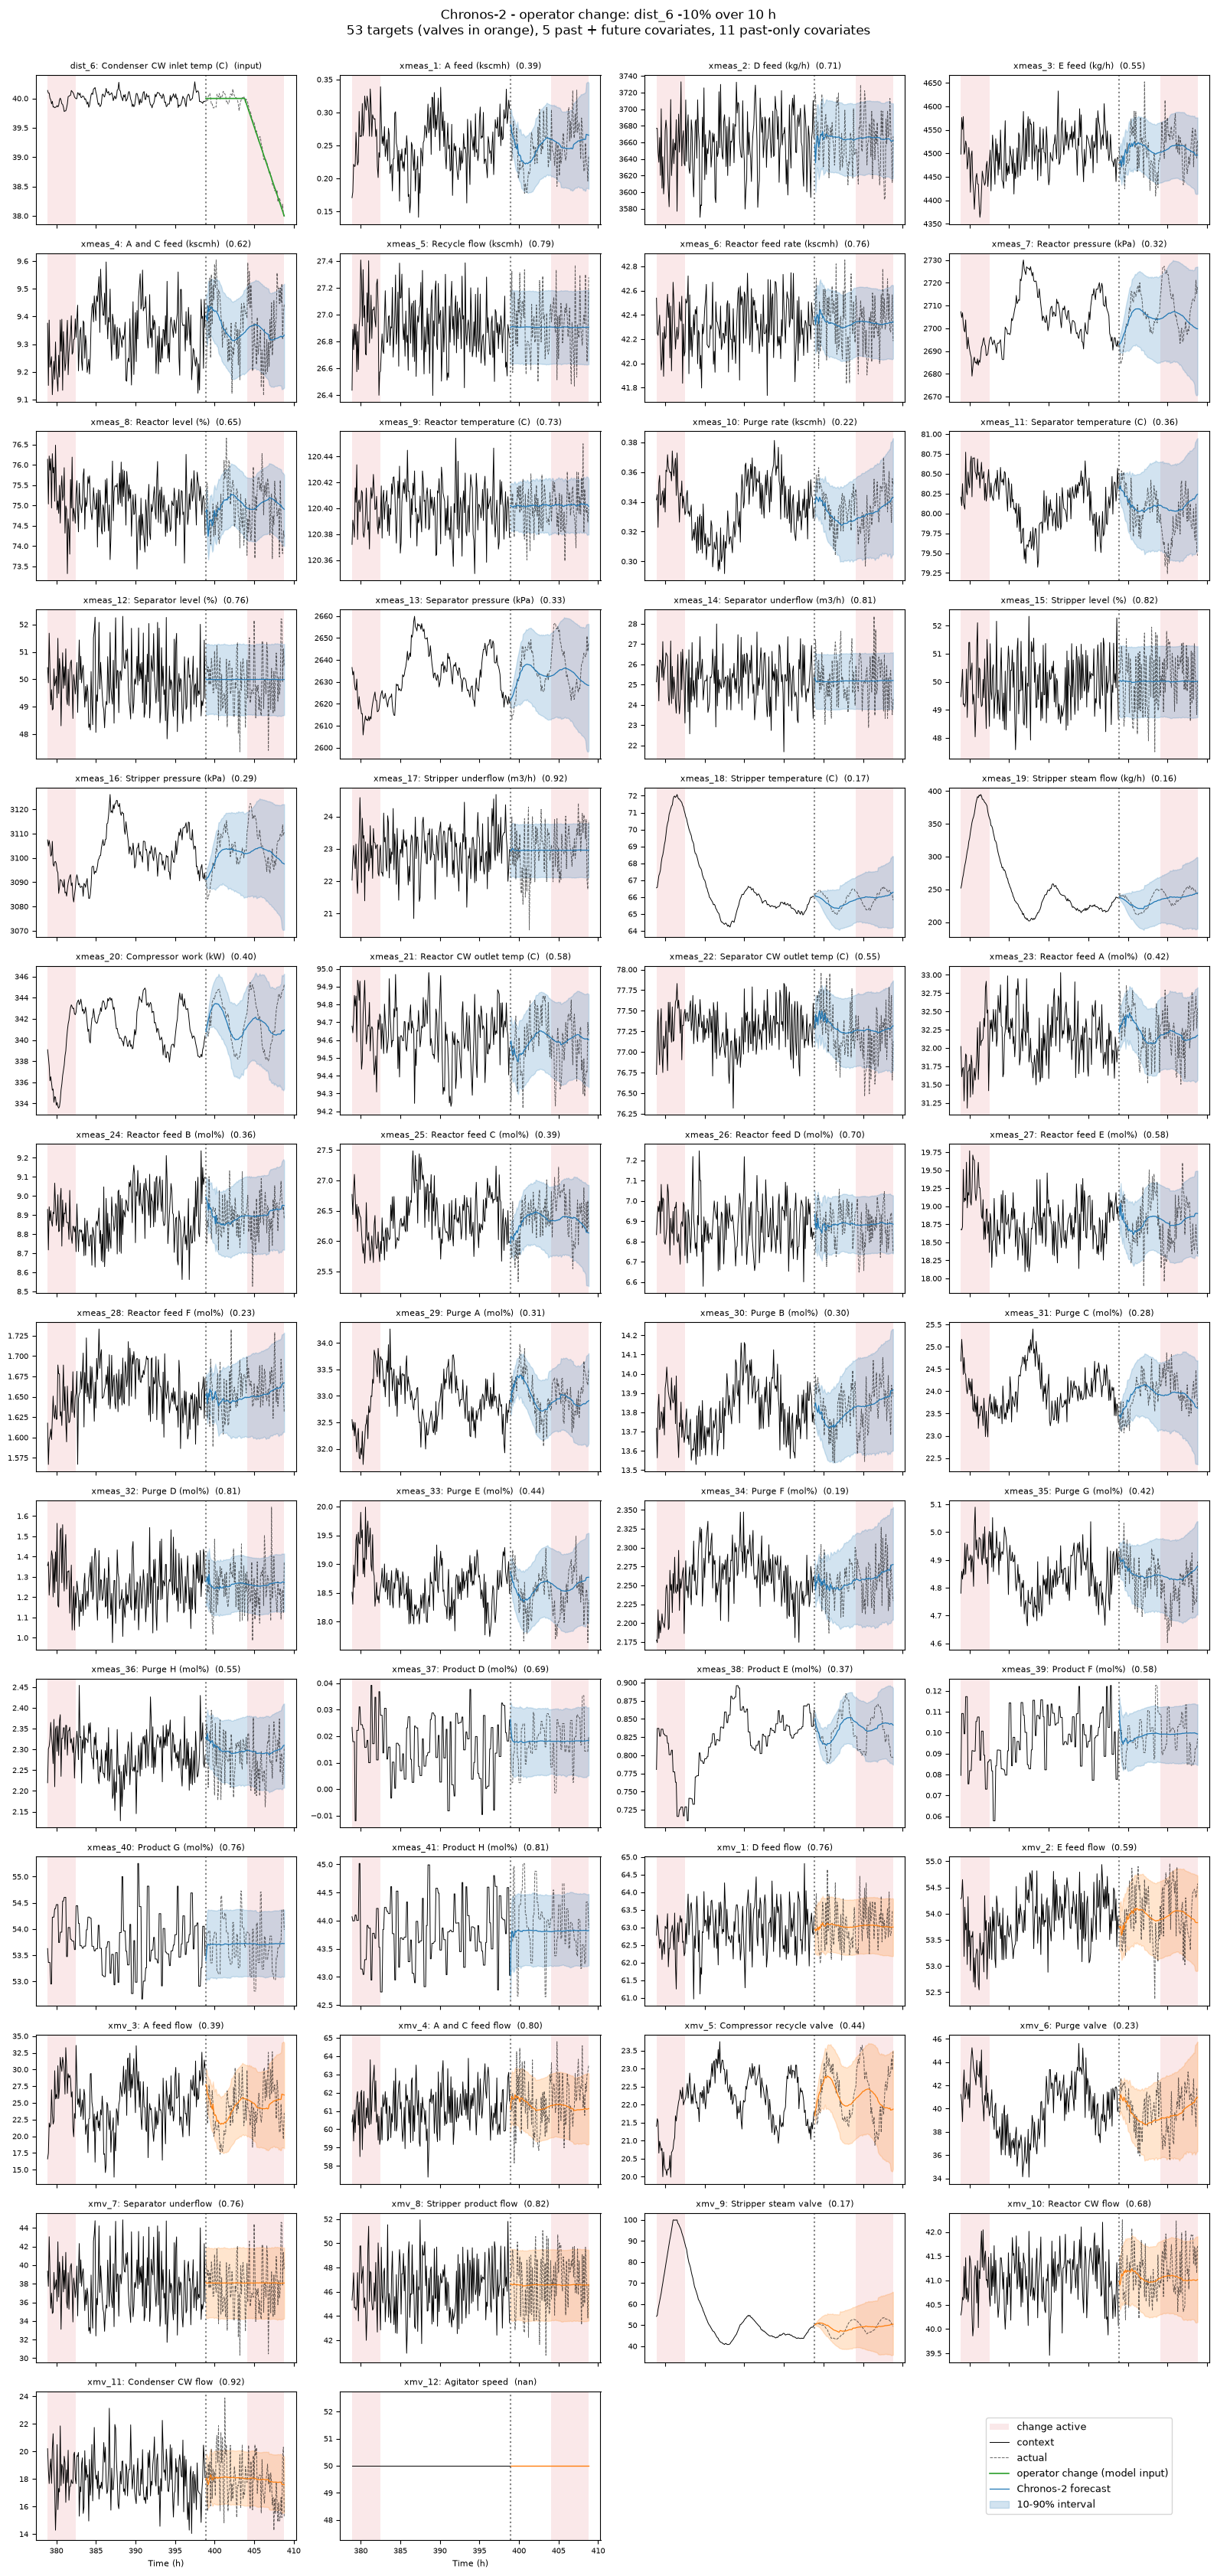

In [8]:
# Plot the changed variables and every target
lead = context_df.iloc[-PLOT_LEAD_IN:]
shown = pd.concat([lead, truth_df])
PANELS = CHANGED + TARGET_COLUMNS

n_rows = -(-(len(PANELS) + 1) // 4)
fig, axes = plt.subplots(n_rows, 4, figsize=(16, 2.4 * n_rows), sharex=True)
for ax, col in zip(axes.ravel(), PANELS):
    ax.fill_between(shown["time_h"], 0, 1, where=shown["change"] != 0, color="tab:red", alpha=0.1,
                    transform=ax.get_xaxis_transform(), step="post", lw=0, label="change active")
    ax.plot(lead["time_h"], lead[col], color="black", lw=0.7, label="context")
    ax.plot(truth_df["time_h"], truth_df[col], color="black", lw=0.7, ls="--", alpha=0.6, label="actual")
    ax.axvline(truth_df["time_h"].iloc[0], color="gray", ls=":")
    if SHUTDOWN:
        ax.axvline(truth_df["time_h"].iloc[-1], color="tab:red", lw=1.2, label="shutdown")
    if col in CHANGED:
        ax.plot(truth_df["time_h"], future_values[col], color="tab:green", lw=1.2, label="operator change (model input)")
        ax.set_title(f"{col}: {LABELS[col]}  (input)", fontsize=8)
    else:
        sub = pred_df[pred_df["target_name"] == col]
        color = "tab:orange" if col.startswith("xmv") else "tab:blue"
        ax.plot(sub["time_h"], sub["predictions"], color=color, lw=0.9, label=f"{MODEL_LABEL} forecast")
        ax.fill_between(sub["time_h"], sub["0.1"], sub["0.9"], color=color, alpha=0.2, label="10-90% interval")
        ax.set_title(f"{col}: {LABELS[col]}  ({accuracy.loc[col, 'scaled MAE (all)']:.2f})", fontsize=8)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(PANELS):]:
    ax.axis("off")
handles, labels = [], []
for ax in [axes.ravel()[0], axes.ravel()[len(CHANGED)]]:
    for h, l in zip(*ax.get_legend_handles_labels()):
        if l not in labels:
            handles.append(h)
            labels.append(l)
axes.ravel()[-1].legend(handles, labels, loc="center", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("Time (h)", fontsize=8)
change_text = ", ".join(f"{col} {percent:+.0f}% over {duration:g} h" for col, percent, _, duration in CHANGES)
fig.suptitle(f"{MODEL_LABEL} - operator change: {change_text}" + ("  (plant shutdown)" if SHUTDOWN else "") + "\n"
             f"{len(TARGET_COLUMNS)} targets (valves in orange), {len(FUTURE_COV)} past + future covariates, "
             f"{len(PAST_ONLY_COV)} past-only covariates", y=1.0)
fig.tight_layout()

In [9]:
# Save results
import os

RESULTS_FILE = "Results/scenarioforecast_chronos2.h5"
ACCURACY_COLUMNS = ["MAE", "scaled MAE (nominal)", "scaled MAE (change)", "scaled MAE (all)",
                    "baseline (nominal)", "baseline (change)", "baseline (all)"]

os.makedirs("Results", exist_ok=True)
with h5py.File(RESULTS_FILE, "w") as f:
    f.attrs["model"] = MODEL_LABEL
    f.attrs["settings"] = json.dumps({
        "data_file": DATA_FILE,
        "changes": CHANGES,
        "truth_seed": TRUTH_SEED,
        "shutdown": bool(SHUTDOWN),
        "split": int(SPLIT),
        "horizon": int(HORIZON),
        "future_dist": FUTURE_DIST,
        "future_covariates": FUTURE_COV,
        "past_only_covariates": PAST_ONLY_COV,
    })

    # Accuracy table
    f.create_dataset("variable", data=list(accuracy.index))
    f.create_dataset("description", data=list(accuracy["description"]))
    for name in ACCURACY_COLUMNS:
        f.create_dataset(name, data=accuracy[name].to_numpy())

    # Forecasts, actual values and the end of the context
    f.create_dataset("time_h", data=truth_df["time_h"].to_numpy())
    f.create_dataset("change", data=truth_df["change"].to_numpy() != 0)
    f.create_dataset("context_time_h", data=lead["time_h"].to_numpy())
    for col in CHANGED:
        f.create_dataset(f"input/{col}", data=future_values[col].to_numpy())
    for col in TARGET_COLUMNS:
        sub = pred_df[pred_df["target_name"] == col]
        f.create_dataset(f"forecast/{col}", data=sub["predictions"].to_numpy())
        f.create_dataset(f"lower/{col}", data=sub["0.1"].to_numpy())
        f.create_dataset(f"upper/{col}", data=sub["0.9"].to_numpy())
        f.create_dataset(f"actual/{col}", data=truth_df[col].to_numpy())
        f.create_dataset(f"context/{col}", data=lead[col].to_numpy())
print(f"Saved {MODEL_LABEL} results to {RESULTS_FILE}")

Saved Chronos-2 results to Results/scenarioforecast_chronos2.h5
